In [1]:
import pandas as pd 
from pathlib import Path 

path = Path("C:\\Users\\ELGRM\\OneDrive\\Desktop\\Hands-On_Machine_Learning_with_Scikit-Learn-Keras-and-TensorFlow-2nd-Edition-Aurelien-Geron\\Processing Sequences Using RNNs and CNNs\\CTA_-_Ridership_-_Daily_Boarding_Totals_20261101.csv")

df = pd.read_csv(path , parse_dates=["service_date"], thousands=",")
df.columns = ["date", "day_type", "bus", "rail", "total"]
df = df.sort_values("date").set_index("date")
df = df.drop("total", axis= 1 )
df = df.drop_duplicates()

In [2]:
df.head()

,day_type,bus,rail
date,,,
2001-01-01,U,297192,126455
2001-01-02,W,780827,501952
2001-01-03,W,824923,536432
2001-01-04,W,870021,550011
2001-01-05,W,890426,557917


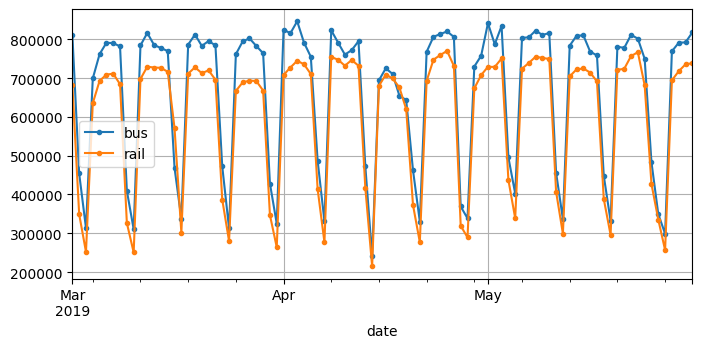

In [3]:
import matplotlib.pyplot as plt

df["2019-03":"2019-05"].plot(grid=True, marker=".", figsize=(8, 3.5))
plt.show()

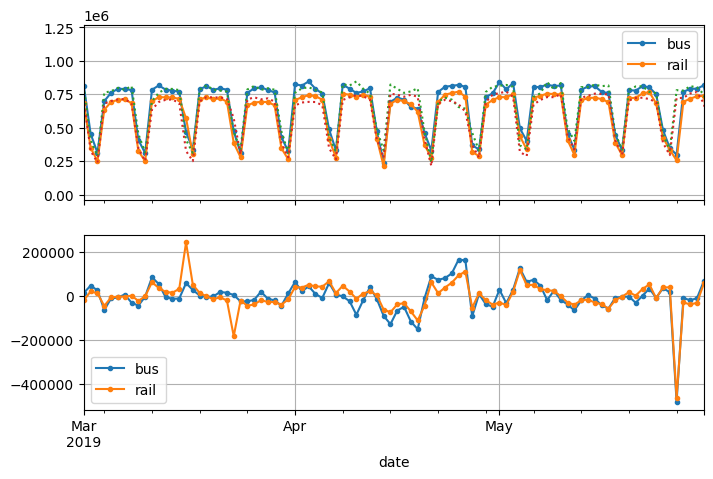

In [4]:
diff_7 = df[["bus" ,"rail"]].diff(7)["2019-03":"2019-05"]

fig , axs  = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
df.plot(ax=axs[0], grid=True, marker=".")
df.shift(7).plot(ax=axs[0], grid=True,legend=False, linestyle=":")
diff_7.plot(ax=axs[1], grid=True, marker=".")
plt.show()

In [5]:
diff_7.abs().mean()

bus     43915.608696
rail    42143.271739
dtype: float64

In [6]:
targets = df[["bus", "rail"]]["2019-03":"2019-05"]
(diff_7 / targets).abs().mean()

bus     0.082938
rail    0.089948
dtype: float64

In [7]:
from statsmodels.tsa.arima.model import ARIMA

origin, today = "2019-01-01", "2019-05-31"

rail_series = df.loc[origin:today]["rail"].asfreq("D")

model = ARIMA(rail_series,
order=(1, 0, 0),
seasonal_order=(0, 1, 1, 7))
model = model.fit()
y_pred = model.forecast()  
y_pred

2019-06-01    427758.626221
Freq: D, dtype: float64

In [8]:
origin, start_date, end_date = "2019-01-01", "2019-03-01", "2019-05-31"
time_period = pd.date_range(start_date, end_date)
rail_series = df.loc[origin:end_date]["rail"].asfreq("D")
y_preds = []
for today in time_period.shift(-1):
    model = ARIMA(rail_series[origin:today],  # train on data up to "today"
            order=(1, 0, 0),
            seasonal_order=(0, 1, 1, 7))
    model = model.fit()  # note that we retrain the model every day!
    y_pred = model.forecast().iloc[0]
    y_preds.append(y_pred)
y_preds = pd.Series(y_preds, index=time_period)
mae = (y_preds - rail_series[time_period]).abs().mean()

In [9]:

import torch


class TimeSeriesDataset(torch.utils.data.Dataset):
    def __init__(self, series , window_size):
        self.series = series
        self.window_size = window_size
    def __len__(self):
        return len(self.series) - self.window_size
    def __getitem__(self, idx):
        if idx >= len(self):
            raise IndexError("dataset index out of range")
        end = idx + self.window_size
        window = self.series[idx:end]
        target = self.series[end]
        return window , target

    
  


In [10]:
my_series = torch.tensor([[0], [1], [2], [3], [4], [5]])
my_dataset = TimeSeriesDataset(my_series, window_size=3)
for window, target in my_dataset:
    print("Window:", window, "Target:", target)

Window: tensor([[0],
        [1],
        [2]]) Target: tensor([3])
Window: tensor([[1],
        [2],
        [3]]) Target: tensor([4])
Window: tensor([[2],
        [3],
        [4]]) Target: tensor([5])


In [11]:
from torch.utils.data import DataLoader

torch.manual_seed(0)
my_loader = DataLoader(my_dataset, batch_size=2, shuffle=True)

for x , y in my_loader:
    print("X:", x, "Y:", y)


X: tensor([[[0],
         [1],
         [2]],

        [[2],
         [3],
         [4]]]) Y: tensor([[3],
        [5]])
X: tensor([[[1],
         [2],
         [3]]]) Y: tensor([[4]])


In [12]:
rail_train = torch.FloatTensor(df[["rail"]]["2016-01":"2018-12"].values / 1e6)
rail_valid = torch.FloatTensor(df[["rail"]]["2019-01":"2019-05"].values / 1e6)
rail_test = torch.FloatTensor(df[["rail"]]["2019-06":].values / 1e6)

In [13]:
window_size = 56
train_dataset = TimeSeriesDataset(rail_train, window_size)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_dataset = TimeSeriesDataset(rail_valid, window_size)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False)
test_dataset = TimeSeriesDataset(rail_test, window_size)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


In [14]:
import torchmetrics
from torch import device

device = device("cuda") if torch.cuda.is_available() else device("cpu")

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=10, factor=0.1):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history


In [15]:
import torch.nn as nn
import torchmetrics

torch.manual_seed(42)
model = nn.Sequential(nn.Flatten(), nn.Linear(window_size, 1)).to(device)
loss_fn = nn.HuberLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.003, momentum=0.9)
metric = torchmetrics.MeanAbsoluteError().to(device)

history = train(model, optimizer, loss_fn, metric, train_loader,
                valid_loader, n_epochs=50)

Epoch 1/50, train loss: 0.0154, train metric: 0.1458, valid metric: 0.1235
Epoch 2/50, train loss: 0.0100, train metric: 0.1117, valid metric: 0.0996
Epoch 3/50, train loss: 0.0075, train metric: 0.0933, valid metric: 0.0795
Epoch 4/50, train loss: 0.0063, train metric: 0.0816, valid metric: 0.0668
Epoch 5/50, train loss: 0.0056, train metric: 0.0741, valid metric: 0.0609
Epoch 6/50, train loss: 0.0053, train metric: 0.0697, valid metric: 0.0550
Epoch 7/50, train loss: 0.0049, train metric: 0.0663, valid metric: 0.0545
Epoch 8/50, train loss: 0.0047, train metric: 0.0636, valid metric: 0.0493
Epoch 9/50, train loss: 0.0045, train metric: 0.0617, valid metric: 0.0457
Epoch 10/50, train loss: 0.0045, train metric: 0.0615, valid metric: 0.0437
Epoch 11/50, train loss: 0.0043, train metric: 0.0586, valid metric: 0.0453
Epoch 12/50, train loss: 0.0042, train metric: 0.0577, valid metric: 0.0420
Epoch 13/50, train loss: 0.0042, train metric: 0.0576, valid metric: 0.0403
Epoch 14/50, train lo

In [16]:
class SimpleRnnModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.memory_cell = nn.Sequential(
            nn.Linear(input_size + hidden_size, hidden_size),
            nn.Tanh(),
       )
        self.output = nn.Linear(hidden_size, output_size)
    def forward(self, X):
        batch_size  , window_size, dimensionlity = X.shape
        X_time_first = X.transpose(0, 1)
        hidden = torch.zeros(batch_size, self.hidden_size, device=X.device)
        for t in X_time_first:
            XH = torch.cat((t, hidden), dim=1)
            hidden = self.memory_cell(XH)
        return self.output(hidden)

torch.manual_seed(42)

univar_model = SimpleRnnModel(input_size=1, hidden_size=32, output_size=1)

In [17]:
class SimpleRnnModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, output_size)
    def forward(self, X):
        outputs, last_state = self.rnn(X)
        return self.output(outputs[:, -1])

In [18]:
df_mulvar = df[["rail", "bus"]] / 1e6  # use both rail & bus series as input
df_mulvar["next_day_type"] = df["day_type"].shift(-1)  # we know tomorrow's type
df_mulvar = pd.get_dummies(df_mulvar, dtype=float)  # one-hot encode day type

In [19]:
mulvar_train = torch.FloatTensor(df_mulvar["2016-01":"2018-12"].values / 1e6)
mulvar_valid = torch.FloatTensor(df_mulvar["2019-01":"2019-05"].values / 1e6)
mulvar_test = torch.FloatTensor(df_mulvar["2019-06":].values / 1e6)

In [20]:
class MulvarTimeSeriesDataset(TimeSeriesDataset):
    def __getitem__(self, idx):
        window, target = super().__getitem__(idx)
        return window, target[:1]

In [21]:
mulvar_train_set = MulvarTimeSeriesDataset(mulvar_train, window_size)
mulvar_train_loader = DataLoader(mulvar_train_set, batch_size=32, shuffle=True)
mulvar_valid_set = MulvarTimeSeriesDataset(mulvar_valid, window_size)
mulvar_valid_loader = DataLoader(mulvar_valid_set, batch_size=32, shuffle=False)
mulvar_test_set = MulvarTimeSeriesDataset(mulvar_test, window_size)
mulvar_test_loader = DataLoader(mulvar_test_set, batch_size=32, shuffle=False)

In [22]:
torch.manual_seed(42)
mulvar_model = SimpleRnnModel(input_size=5, hidden_size=32, output_size=1)
mulvar_model = mulvar_model.to(device)

In [25]:
class ForecastAheadDataset(TimeSeriesDataset):
    def __len__(self):
        return len(self.series) - self.window_size - 14 + 1
    def __getitem__(self, idx):
        end = idx + self.window_size  # 1st index after window
        window = self.series[idx : end]
        target = self.series[end : end + 14, 0]  # 0 = rail ridership
        return window, target

In [26]:
ahead_train_set = ForecastAheadDataset(mulvar_train, window_size)
ahead_train_loader = DataLoader(ahead_train_set, batch_size=32, shuffle=True)
ahead_valid_set = ForecastAheadDataset(mulvar_valid, window_size)
ahead_valid_loader = DataLoader(ahead_valid_set, batch_size=32, shuffle=False)
ahead_test_set = ForecastAheadDataset(mulvar_test, window_size)
ahead_test_loader = DataLoader(ahead_test_set, batch_size=32, shuffle=False)

In [27]:
torch.manual_seed(42)
ahead_model = SimpleRnnModel(input_size=5, hidden_size=32, output_size=14)
ahead_model = ahead_model.to(device)

In [28]:
ahead_model.eval()
with torch.no_grad():
    window = mulvar_valid[:window_size]  # shape [56, 5]
    X = window.unsqueeze(dim=0)            
    # shape [1, 56, 5]
    Y_pred = ahead_model(X.to(device))     
    # shape [1, 14]

In [29]:
class Seq2SeqDataset(ForecastAheadDataset):
    def __getitem__(self, idx):
        end = idx + self.window_size  # 1st index after window
        window = self.series[idx : end]
        target_period = self.series[idx + 1 : end + 14, 0]
        target = target_period.unfold(dimension=0, size=14, step=1)
        return window, target

In [30]:
torch.tensor([0, 1, 2, 3, 4, 5]).unfold(dimension=0, size=4, step=1)

tensor([[0, 1, 2, 3],
        [1, 2, 3, 4],
        [2, 3, 4, 5]])

In [31]:
seq_train_set = Seq2SeqDataset(mulvar_train, window_size)
seq_train_loader = DataLoader(seq_train_set, batch_size=32, shuffle=True)
seq_valid_set = Seq2SeqDataset(mulvar_valid, window_size)
seq_valid_loader = DataLoader(seq_valid_set, batch_size=32, shuffle=False)
seq_test_set = Seq2SeqDataset(mulvar_test, window_size)
seq_test_loader = DataLoader(seq_test_set, batch_size=32, shuffle=False)

In [32]:
class Seq2SeqRnnModel(SimpleRnnModel):
    def forward(self, X):
        outputs, last_state = self.rnn(X)
        return self.output(outputs)

    
torch.manual_seed(42)
seq_model = Seq2SeqRnnModel(input_size=5, hidden_size=32, output_size=14)
seq_model = seq_model.to(device)

In [33]:
from torch import nn
from torch import device

class LstmModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.memory_cell = nn.LSTMCell(input_size, hidden_size)
        self.output = nn.Linear(hidden_size, output_size)
    def forward(self, X):
        batch_size, window_length, dimensionality = X.shape
        X_time_first = X.transpose(0, 1)
        H = torch.zeros(batch_size, self.hidden_size, device=X.device)
        C = torch.zeros(batch_size, self.hidden_size, device=X.device)
        for X_t in X_time_first:
            H, C = self.memory_cell(X_t, (H, C))
        return self.output(H)